In [1]:
# 01 - Importar librerías y recargar configuración
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
from statsmodels.stats.diagnostic import linear_reset
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
from sklearn.model_selection import KFold, RepeatedKFold
import src.config as cfg
import matplotlib as mpl


    
np.set_printoptions(suppress=True)
pd.options.display.max_columns = None
pd.options.display.max_colwidth = None
pd.options.display.max_rows = None


In [2]:
# Helper: escape special LaTeX characters for safe printing in tables and captions
def escape_latex(s):
    if s is None:
        return ''
    s = str(s)
    # Order matters: replace backslash first
    replacements = {
        '\\': '\\textbackslash{}',
        '&': '\\&',
        '%': '\\%',
        '$': '\\$',
        '#': '\\#',
        '_': '\\_',
        '{': '\\{',
        '}': '\\}',
        '~': '\\textasciitilde{}',
        '^': '\\^{}',
    }
    for k, v in replacements.items():
        s = s.replace(k, v)
    return s

# End helper


In [3]:
# 02 - Cargar dataset
df = pd.read_csv('data/dataset_mrh_0.9.csv')
df.head()


,Species,Parameter,DAF,Reference,Obs,Quote,DOI,link,Cluster,Data_curator,GA(H+14)
0,Mouse,GE volume peak,15.75,"Charvet et al., 2017",NaN,"""The GE peak size occurs between the ages of ED 15.5 to ED 16 in mice, ED 80 in the macaque, and between GW 21 and 27 in humans. The growth trajectories from high-resolution diffusion MR scans also demonstrate that the peak in GE size occurs between GW 20 and GW 21 in humans (figure 5)""",https://doi.org/10.1098/rspb.2017.1169,NaN,Brain,Cottam 2024,NaN
1,Mouse,Cortical proliferative zone volume peak,15.00,"Charvet et al., 2017",NaN,"""The peak size of the CPP occurs between ED 14.5 and 15.5 in mice, on approximately ED 90 in macaques and on ED 182 in humans.""",https://doi.org/10.1098/rspb.2017.1169,NaN,Brain,Cottam 2024,NaN
2,Human,GE volume peak,154.00,"Charvet et al., 2017",NaN,"""The GE peak size occurs between the ages of ED 15.5 to ED 16 in mice, ED 80 in the macaque, and between GW 21 and 27 in humans. The growth trajectories from high-resolution diffusion MR scans also demonstrate that the peak in GE size occurs between GW 20 and GW 21 in humans (figure 5)""",https://doi.org/10.1098/rspb.2017.1169,NaN,Brain,Cottam 2024,168.0
3,Human,Cortical proliferative zone volume peak,168.00,"Charvet et al., 2017",NaN,"""The peak size of the CPP occurs between ED 14.5 and 15.5 in mice, on approximately ED 90 in macaques and on ED 182 in humans.""",https://doi.org/10.1098/rspb.2017.1169,NaN,Brain,Cottam 2024,182.0
4,Mouse,Corpus callosum peak volume,30.00,"Charvet et al., 2020",NaN,figure 4,https://doi.org/10.1093/cercor/bhz178,NaN,Brain,Cottam 2024,NaN


In [4]:
# 03 - Pivotear datos y obtener valores de nacimiento
df_pivot = df.pivot_table(index='Parameter', columns='Species', values='DAF', aggfunc='mean').reset_index()
human_birth, mouse_birth, rat_birth = cfg.get_birth_values(df_pivot)
df_pivot.head()


Species,Parameter,Human,Mouse,Rat
0,1st 7 rills chondrified and in contact with sternum,51.0,14.50,NaN
1,1st and 2nd pharyngeal pouches,23.0,8.33,NaN
2,1st cartilage in otic capsule,48.0,14.50,NaN
3,1st pharyngeal pouch,21.0,8.33,NaN
4,3 bronchial areas in right lung,35.0,11.50,NaN


In [5]:
# 04 - Preparar datos base para los ajustes entre humano y roedores
# Datos base para los ajustes entre humano y roedores
fit_mouse = df_pivot[['Human', 'Mouse']].dropna()
fit_rat = df_pivot[['Human', 'Rat']].dropna()



In [6]:
# 05 - Cargar definiciones de modelos y configuración visual desde config
mod_log = cfg.mod_log
mod_pot_const = cfg.mod_pot_const
mod_pot = cfg.mod_pot
mod_quarter_const = cfg.mod_quarter_const
mod_quarter = cfg.mod_quarter
colors_cfg = cfg.colors
modelos_diccionario = cfg.MODELS
FS_TITLE  = cfg.FS_TITLE
FS_LABEL  = cfg.FS_LABEL
FS_LEGEND = cfg.FS_LEGEND
FS_TICK   = cfg.FS_TICK
FS_PANEL  = cfg.FS_PANEL






In [7]:
# 06 - Definición: _wls_fit_single (ajuste iterativo WLS con estimación de varianza)
def _wls_fit_single(func, x, y, p0, maxfev=30000):
    try:
        p_ols, _ = curve_fit(func, x, y, p0=p0, maxfev=maxfev)
    except RuntimeError:
        return None
    y_ols = func(x, *p_ols)
    resid2 = np.maximum((y - y_ols) ** 2, np.finfo(float).eps)
    log_x = np.log(np.maximum(x, np.finfo(float).eps))
    Z = sm.add_constant(log_x)
    var_fit = sm.OLS(np.log(resid2), Z).fit()
    c0, c1 = var_fit.params[0], var_fit.params[1]
    sigma2_hat = np.maximum(np.exp(var_fit.predict(Z)), np.finfo(float).eps)
    sigma_hat = np.sqrt(sigma2_hat)
    try:
        p_wls, _ = curve_fit(func, x, y, p0=p_ols, sigma=sigma_hat, absolute_sigma=False, maxfev=maxfev)
    except RuntimeError:
        return None
    y_wls = func(x, *p_wls)
    weights = 1.0 / sigma2_hat
    wsrs = np.sum(weights * (y - y_wls) ** 2)
    return p_wls, y_wls, weights, wsrs, sigma2_hat, c0, c1



In [8]:
# 07 - Función comparar_no_lineales_loocv (WLS + LOOCV)
def comparar_no_lineales_loocv(x, y, especie):
    """
    Compara modelos no lineales por especie usando WLS y Leave-One-Out CV (LOOCV).
    
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    if not np.all(np.isfinite(x)):
        raise ValueError("x contiene valores no finitos (NaN o ±Inf).")
    if not np.all(np.isfinite(y)):
        raise ValueError("y contiene valores no finitos (NaN o ±Inf).")
    if np.any(x <= 0):
        raise ValueError("x contiene valores <= 0, incompatibles con los modelos logarítmicos y de potencia.")
    
    # Construir la lista de modelos desde cfg.MODELS para mantener una única fuente de verdad.
    # Elegimos el orden que antes estaba codificado: Power+c, Power, Log, Quarter+c, Quarter
    model_order = ['M3', 'M1', 'M5', 'M4', 'M2']
    models = []
    for mid in model_order:
        mspec = cfg.MODELS.get(mid)
        if mspec is None:
            continue
        name = mspec.get('name', mid)
        eq = mspec.get('equation', '')
        eqnum = mspec.get('equation_number')
        p0 = list(mspec.get('initial_params', []))
        func_name = mspec.get('function')
        # resolve function object if stored as string
        func = getattr(cfg, func_name) if isinstance(func_name, str) and hasattr(cfg, func_name) else func_name
        models.append((mid, name, eq, eqnum, func, p0))
    
    indices = np.arange(len(y))
    rows = []
    
    print(f"⚠️ Ejecutando LOOCV para {especie} ({len(y)} muestras). Esto puede tomar unos minutos...\n")
    
    for mid, name, equation, eqnum, func, p0 in models:
        k = len(p0) 
        weighted_sq_sum = 0.0
        weight_sum = 0.0
        n_failed = 0
        
        # --- LEAVE-ONE-OUT CROSS-VALIDATION ---
        for i in range(len(y)):
            test_idx = np.array([i])
            train_idx = np.setdiff1d(indices, test_idx)
            
            x_train, y_train = x[train_idx], y[train_idx]
            x_test,  y_test  = x[test_idx],  y[test_idx]
            
            result = _wls_fit_single(func, x_train, y_train, p0=p0, maxfev=40000)
            
            if result is None or result[0] is None:
                n_failed += 1
                continue
                
            p_wls, _, _, _, _, c0, c1 = result 
            
            y_pred = func(x_test, *p_wls)
            sigma2_test = np.maximum(np.exp(c0 + c1 * np.log(x_test)), np.finfo(float).eps)
            weights_test = 1.0 / sigma2_test
            # Acumular sumas ponderadas (no la raíz por fold) para no promediar RMSEs individuales
            weighted_sq_sum += np.sum(weights_test * (y_test - y_pred)**2)
            weight_sum += np.sum(weights_test)
            
        # --- ESTADÍSTICOS DE LOOCV (WRMSE global sobre todos los folds) ---
        n_success = len(y) - n_failed
        if n_success == 0 or weight_sum == 0:
            cv_wrmse_mean = np.inf
        else:
            cv_wrmse_mean = np.sqrt(weighted_sq_sum / weight_sum)
            
        # --- AJUSTE IN-SAMPLE ---
        result_full = _wls_fit_single(func, x, y, p0=p0, maxfev=40000)
        
        if result_full is None or result_full[0] is None:
            wrmse_in = np.inf
        else:
            _, _, weights_full, wsrs_full, _, _, _ = result_full 
            wrmse_in = np.sqrt(wsrs_full / np.sum(weights_full))
            
        rows.append({
            'Model_ID': mid,
            'Model': name,
            'Eq': f"({eqnum})" if eqnum is not None else '-',
            'Equation': equation,
            'k': k,
            'In-sample WRMSE': wrmse_in,
            'CV-WRMSE': cv_wrmse_mean,
            'Fallas': n_failed
        })
        
    # --- CONSTRUIR TABLA (Sin regla 1-SE) ---
    tabla = pd.DataFrame(rows).sort_values(by=['CV-WRMSE', 'k']).reset_index(drop=True)
    
    # Identificar el mínimo absoluto
    min_wrmse = tabla['CV-WRMSE'].min()
        
    # --- FORMATEO PARA IMPRESIÓN ---
    tabla_print = tabla.copy()
    tabla_print['In-sample WRMSE'] = tabla_print['In-sample WRMSE'].apply(lambda x: f"{x:.4f}" if np.isfinite(x) else "Fallo")
    
    # Resaltar el mejor modelo
    tabla_print['CV-WRMSE'] = tabla_print.apply(
        lambda row: f"**{float(row['CV-WRMSE']):.4f}**" if row['CV-WRMSE'] == min_wrmse else f"{float(row['CV-WRMSE']):.4f}", 
        axis=1
    )
    
    columnas_mostrar = ['Model_ID','Model','Eq', 'Equation', 'k', 'In-sample WRMSE', 'CV-WRMSE', 'Fallas']
    
    print(f'\n{"="*85}')
    print(f' {especie.upper()} | Comparación WLS No-Lineal LOOCV ')
    print(f'{"="*85}')
    print(tabla_print[columnas_mostrar].to_string(index=False))
    print(f'{"="*85}\n')
    
    return tabla


In [9]:
# 08 - Ejecutar LOOCV para rata y ratón
cv_rat_loocv = comparar_no_lineales_loocv(fit_rat['Human'],   fit_rat['Rat'],   especie='Rat')
cv_mouse_loocv = comparar_no_lineales_loocv(fit_mouse['Human'], fit_mouse['Mouse'], especie='Mouse')


⚠️ Ejecutando LOOCV para Rat (183 muestras). Esto puede tomar unos minutos...


 RAT | Comparación WLS No-Lineal LOOCV 
Model_ID       Model  Eq            Equation  k In-sample WRMSE   CV-WRMSE  Fallas
      M3   Power + c (3)     $y = b x^a + c$  3          2.2603 **2.3326**       0
      M4 Quarter + c (4) $y = b x^{1/4} + c$  2          2.6099     2.6600       0
      M5 Logarithmic (5)  $y = b \ln(x) + c$  2          3.1025     3.1116       0
      M1       Power (1)         $y = b x^a$  2          3.7060     3.8158       0
      M2     Quarter (2)     $y = b x^{1/4}$  1          5.3935     5.4743       0

⚠️ Ejecutando LOOCV para Mouse (195 muestras). Esto puede tomar unos minutos...


 MOUSE | Comparación WLS No-Lineal LOOCV 
Model_ID       Model  Eq            Equation  k In-sample WRMSE   CV-WRMSE  Fallas
      M4 Quarter + c (4) $y = b x^{1/4} + c$  2          1.3398 **1.3334**       0
      M3   Power + c (3)     $y = b x^a + c$  3          1.2915     1.3467       0
      M5

In [10]:
# 09A - Preparar tabla combinada LOOCV y guardar CSV
def prepare_combined_loocv_data(tabla_rat, tabla_mouse):
    import re
    
    # Use model names from cfg.MODELS (short names) for table display
    model_names = {}
    for mid, mspec in cfg.MODELS.items():
        name = mspec.get('name')
        if name:
            model_names[name] = name

    # Build a lookup map from cfg.MODELS only (no EQUATION_MAP)
    def _normalize_local(s):
        if s is None:
            return ''
        t = str(s)
        t = t.replace('$', '')
        t = t.replace('\\', '')
        t = t.replace('{', '')
        t = t.replace('}', '')
        t = re.sub(r"\s+", ' ', t).strip()
        t = t.replace(' = ', '=')
        t = t.replace(' + ', '+')
        t = t.replace(' ^', '^')
        return t.lower()

    _local_eq_map = {}
    for mid, mspec in cfg.MODELS.items():
        eqtxt = mspec.get('equation')
        name = mspec.get('name')
        eqnum = mspec.get('equation_number')
        if eqtxt:
            _local_eq_map[_normalize_local(eqtxt)] = str(eqnum) if eqnum is not None else str(mid)
        if name:
            _local_eq_map[_normalize_local(name)] = str(eqnum) if eqnum is not None else str(mid)

    dfs_procesados = []
    for df, especie in [(tabla_rat, 'Rat'), (tabla_mouse, 'Mouse')]:
        df_temp = df.copy()
        df_temp['Species'] = especie
        # Map model names using the short names from cfg.MODELS; fall back to existing value
        df_temp['Model'] = df_temp['Model'].map(model_names).fillna(df_temp['Model'])
        
        # SOLUCIÓN: Limpiar posibles escapes rotos ANTES de mapear.
        if 'Equation' in df_temp.columns:
            df_temp['Equation'] = df_temp['Equation'].astype(str).str.replace('\\\\textbackslash{}', '\\', regex=False)

        # Use the lookup derived from cfg.MODELS only
        def _map_equation_val(s):
            norm = _normalize_local(s)
            return _local_eq_map.get(norm, s)

        if 'Equation' in df_temp.columns:
            df_temp['Equation'] = df_temp['Equation'].apply(lambda s: _map_equation_val(s))

        dfs_procesados.append(df_temp)

    df_combined = pd.concat(dfs_procesados, ignore_index=True)
    
    # Guardar la tabla combinada como CSV en el directorio results
    df_combined.to_csv('results/loocv_results_separately.csv', index=False, encoding='utf-8')
    print("✅ CSV (LOOCV) guardado en: results/loocv_results_separately.csv")
    
    return df_combined

# Ejecutar la función y guardar el resultado en una variable para la siguiente celda
df_combined_loocv = prepare_combined_loocv_data(cv_rat_loocv, cv_mouse_loocv)

✅ CSV (LOOCV) guardado en: results/loocv_results_separately.csv


In [11]:
# 09.5 - Calcular parámetros WLS por especie (función tabla_parametros_wls)
def tabla_parametros_wls(x, y, especie, maxfev=40000):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = (x > 0) & np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]

    # Construir models_info a partir de cfg.MODELS para mantener una única fuente de verdad
    model_order = ['M3', 'M1', 'M5', 'M4', 'M2']

    # Mapa local para nombres de parámetros (símbolos usados en el resto del notebook)
    param_name_map = {
        'Power + c': ['a', 'b', 'c'],
        'Power': ['a', 'b'],
        'Logarithmic': ['a', 'c'],
        'Quarter + c': ['b', 'c'],
        'Quarter': ['b'],
    }

    models_info = []
    for mid in model_order:
        mspec = cfg.MODELS.get(mid)
        if mspec is None:
            continue
        name = mspec.get('name', mid)
        p0 = list(mspec.get('initial_params', []))
        func_name = mspec.get('function')
        func = getattr(cfg, func_name) if isinstance(func_name, str) and hasattr(cfg, func_name) else func_name
        eqnum = mspec.get('equation_number')
        param_names = param_name_map.get(name, [f'p{i+1}' for i in range(len(p0))])
        models_info.append((name, func, p0, param_names, eqnum))

    rows = []
    # Si no quedan datos válidos, devolver filas con NaN para cada modelo/parametro
    if x.size == 0:
        for name, _, _, param_names, eqnum in models_info:
            for pname in param_names:
                rows.append(dict(Especie=especie, Modelo=name, Parámetro=pname,
                                 Estimación=np.nan, Error_SE=np.nan,
                                 IC95_inf=np.nan, IC95_sup=np.nan, t=np.nan,
                                 Eq=(f"({eqnum})" if eqnum is not None else '-')))
        return pd.DataFrame(rows)

    for name, func, p0, param_names, eqnum in models_info:
        # OLS pass to seed variance model (capturamos cualquier excepción)
        try:
            p_ols, _ = curve_fit(func, x, y, p0=p0, maxfev=maxfev)
        except Exception as e:
            for pname in param_names:
                rows.append(dict(Especie=especie, Modelo=name, Parámetro=pname,
                                 Estimación=np.nan, Error_SE=np.nan,
                                 IC95_inf=np.nan, IC95_sup=np.nan, t=np.nan,
                                 Eq=(f"({eqnum})" if eqnum is not None else '-')))
            continue

        try:
            y_ols   = func(x, *p_ols)
            resid2  = np.maximum((y - y_ols) ** 2, np.finfo(float).eps)
            Z       = sm.add_constant(np.log(np.maximum(x, np.finfo(float).eps)))
            var_fit = sm.OLS(np.log(resid2), Z).fit()
            sigma2  = np.maximum(np.exp(var_fit.predict(Z)), np.finfo(float).eps)
            sigma   = np.sqrt(sigma2)
        except Exception as e:
            for pname in param_names:
                rows.append(dict(Especie=especie, Modelo=name, Parámetro=pname,
                                 Estimación=np.nan, Error_SE=np.nan,
                                 IC95_inf=np.nan, IC95_sup=np.nan, t=np.nan,
                                 Eq=(f"({eqnum})" if eqnum is not None else '-')))
            continue

        # WLS pass – keep pcov for inference
        try:
            p_wls, pcov = curve_fit(func, x, y, p0=p_ols, sigma=sigma, absolute_sigma=False, maxfev=maxfev)
        except Exception as e:
            for pname in param_names:
                rows.append(dict(Especie=especie, Modelo=name, Parámetro=pname,
                                 Estimación=np.nan, Error_SE=np.nan,
                                 IC95_inf=np.nan, IC95_sup=np.nan, t=np.nan,
                                 Eq=(f"({eqnum})" if eqnum is not None else '-')))
            continue

        # Calcular errores estándar de forma segura
        try:
            se = np.sqrt(np.abs(np.diag(pcov))) if pcov is not None else np.full(len(p_wls), np.nan)
            if se.shape[0] != len(p_wls):
                se = np.full(len(p_wls), np.nan)
        except Exception:
            se = np.full(len(p_wls), np.nan)

        for pname, est, se_i in zip(param_names, p_wls, se):
            rows.append(dict(
                Especie     = especie,
                Modelo      = name,
                Parámetro   = pname,
                Estimación  = est,
                Error_SE    = se_i,
                IC95_inf    = est - 1.96 * se_i if pd.notna(se_i) and np.isfinite(se_i) else np.nan,
                IC95_sup    = est + 1.96 * se_i if pd.notna(se_i) and np.isfinite(se_i) else np.nan,
                t           = est / se_i if pd.notna(se_i) and se_i > 0 else np.nan,
                Eq          = (f"({eqnum})" if eqnum is not None else '-')
            ))
    return pd.DataFrame(rows)

# Ejecutar para rata y ratón y combinar
df_rat_params   = tabla_parametros_wls(fit_rat['Human'],   fit_rat['Rat'],   especie='Rat')
df_mouse_params = tabla_parametros_wls(fit_mouse['Human'], fit_mouse['Mouse'], especie='Mouse')
tabla_params = pd.concat([df_rat_params, df_mouse_params], ignore_index=True)

# Mostrar y guardar CSV
if len(tabla_params) == 0:
    print("No hay parámetros calculados; tabla vacía.")
else:
    display(
        tabla_params.rename(columns={
            'Error_SE': 'Error estándar',
            'IC95_inf': 'IC95% inferior',
            'IC95_sup': 'IC95% superior',
        }).round(4)
    )
    csv_path = 'results/parameters_wlss_separately.csv'
    tabla_params.to_csv(csv_path, index=False, encoding='utf-8')
    print(f"✅ CSV de parámetros guardado en: {csv_path}")

,Especie,Modelo,Parámetro,Estimación,Error estándar,IC95% inferior,IC95% superior,t,Eq
0,Rat,Power + c,a,0.2480,0.0490,0.1520,0.3441,5.0603,(3)
1,Rat,Power + c,b,10.5835,4.3261,2.1043,19.0627,2.4464,(3)
2,Rat,Power + c,c,-12.7928,5.9763,-24.5064,-1.0793,-2.1406,(3)
3,Rat,Power,a,0.3495,0.0108,0.3283,0.3707,32.3288,(1)
4,Rat,Power,b,3.8890,0.2118,3.4740,4.3041,18.3635,(1)
5,Rat,Logarithmic,a,7.8213,0.2929,7.2471,8.3954,26.6994,(5)
6,Rat,Logarithmic,c,-14.8238,1.1485,-17.0749,-12.5727,-12.9068,(5)
7,Rat,Quarter + c,b,10.3716,0.3630,9.6602,11.0831,28.5715,(4)
8,Rat,Quarter + c,c,-12.4535,0.9603,-14.3357,-10.5713,-12.9681,(4)
9,Rat,Quarter,b,6.4539,0.1282,6.2026,6.7051,50.3467,(2)


✅ CSV de parámetros guardado en: results/parameters_wlss_separately.csv


Panel saved as 'figures/panel2.pdf' and 'figures/panel2.tiff'


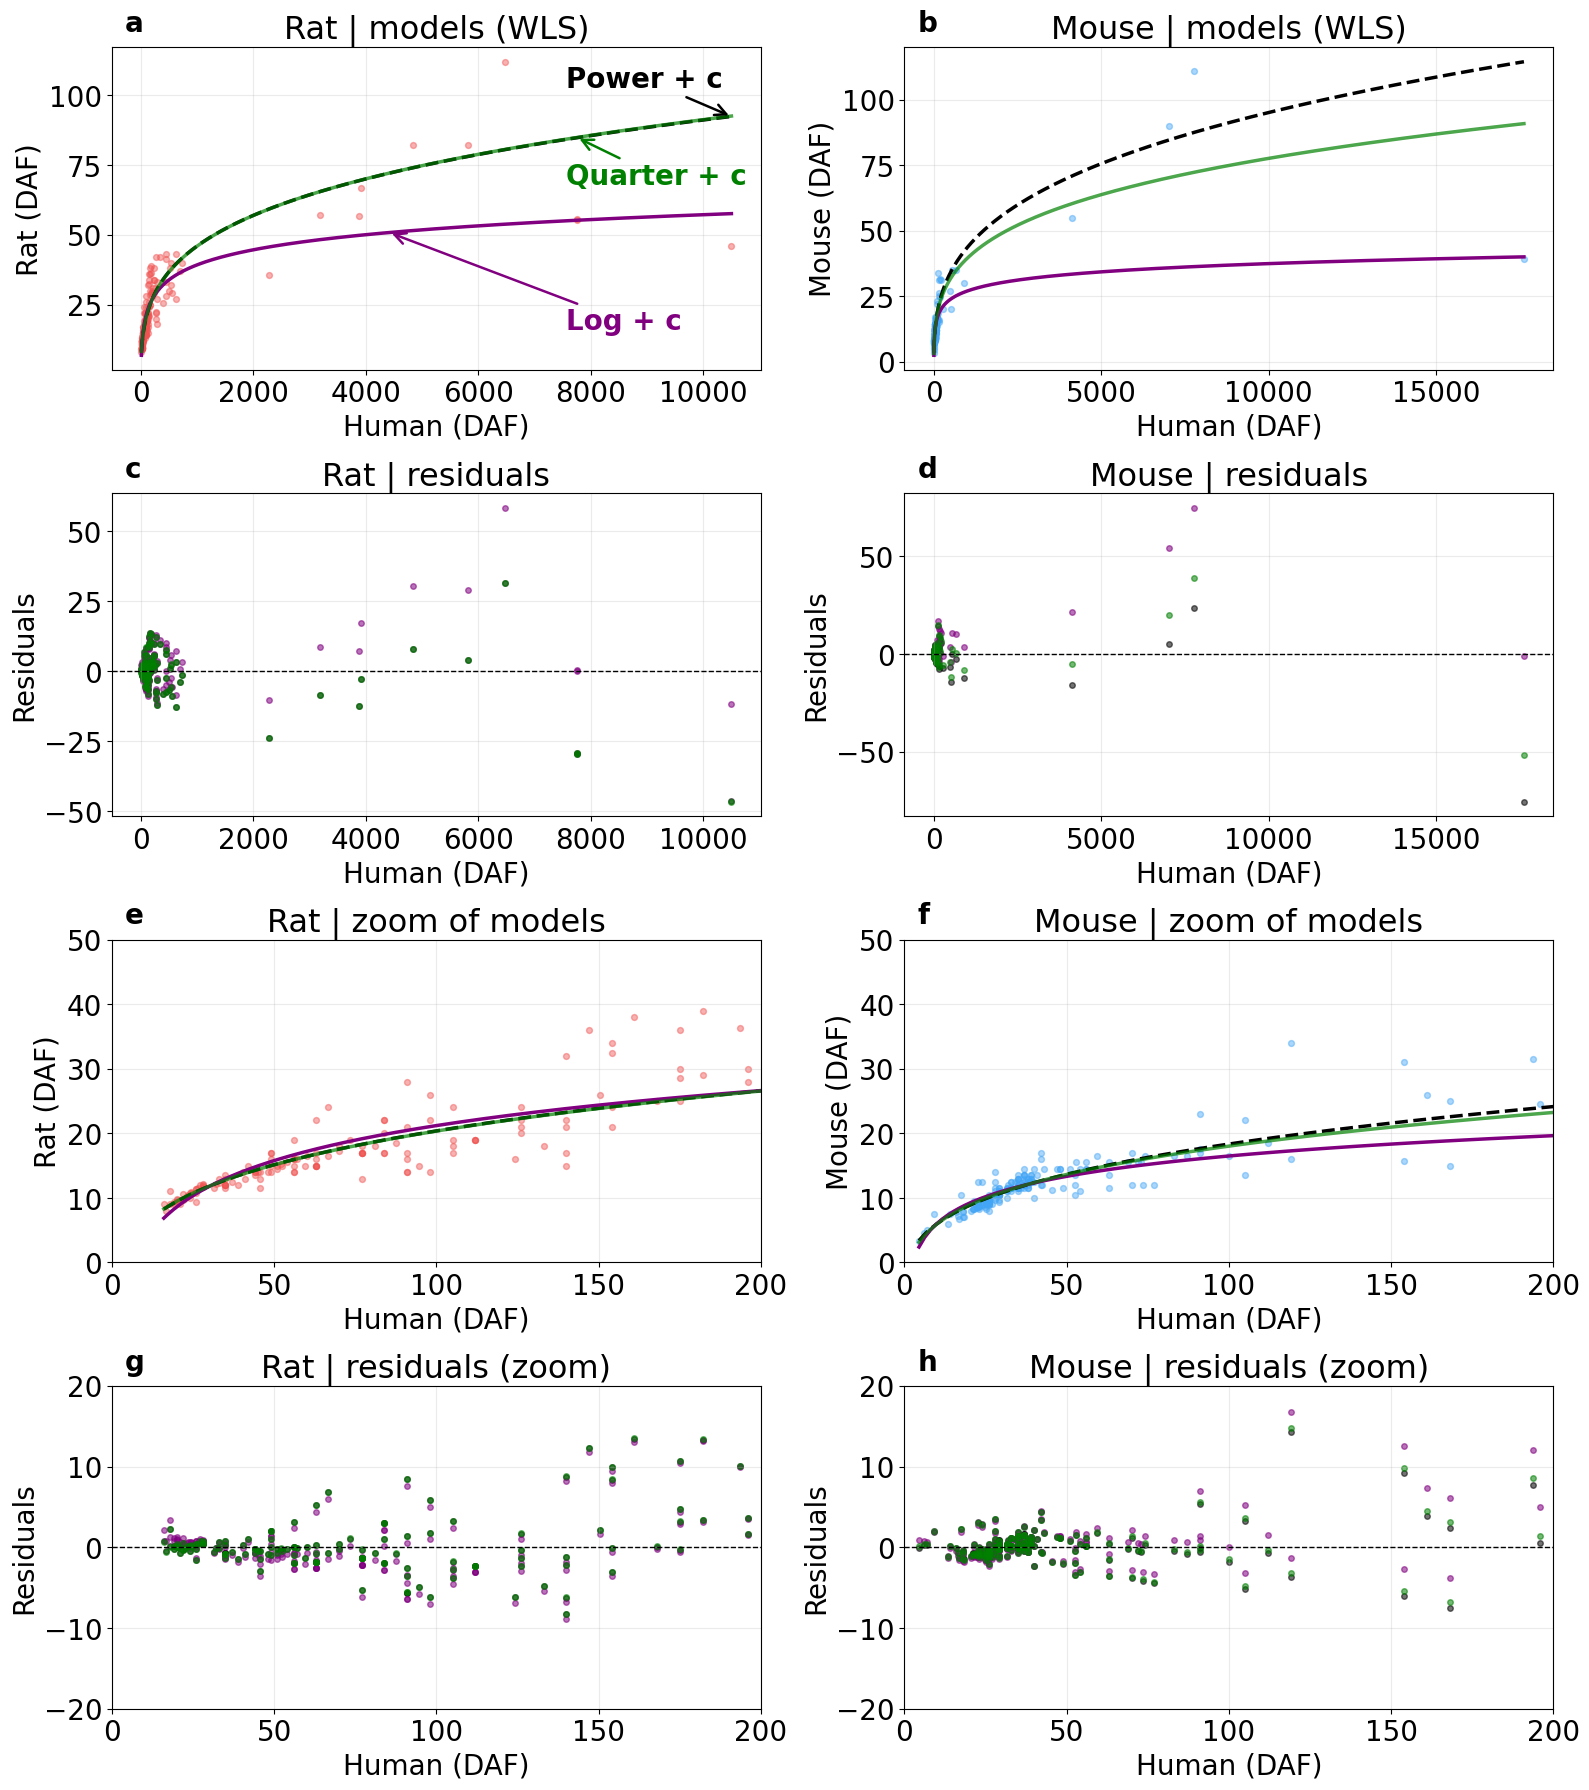

WLS parameters (mod_pot_const)


,Species,a,b,c
0,Rat,0.248025,10.583523,-12.792844
1,Mouse,0.310245,5.797331,-5.860290


Species        a         b          c
    Rat 0.248025 10.583523 -12.792844
  Mouse 0.310245  5.797331  -5.860290


In [12]:
# 11 - Funciones de plotting y generar panel final (figuras y resumen)


subplot_letters_cfg = {
    'labels': list('abcdefghijklmnopqrstuvwxyz'),
    'x': 0.02,
    'y': 1.03,
    'fontsize': FS_PANEL,
    'fontweight': 'bold',
    'ha': 'left',
    'va': 'bottom',
}

def _add_subplot_letters(axes, letters_cfg):
    labels = letters_cfg.get('labels', list('abcdefghijklmnopqrstuvwxyz'))
    x = letters_cfg.get('x', 0.02)
    y = letters_cfg.get('y', 1.03)
    fontsize = letters_cfg.get('fontsize', 11)
    fontweight = letters_cfg.get('fontweight', 'bold')
    ha = letters_cfg.get('ha', 'left')
    va = letters_cfg.get('va', 'bottom')

    for i, ax in enumerate(np.ravel(axes)):
        if i >= len(labels):
            break
        ax.text(
            x,
            y,
            labels[i],
            transform=ax.transAxes,
            fontsize=fontsize,
            fontweight=fontweight,
            ha=ha,
            va=va,
        )

def _fit_three_models(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if not np.all(np.isfinite(x)):
        raise ValueError("x contiene NaN o infinitos.")
    if not np.all(np.isfinite(y)):
        raise ValueError("y contiene NaN o infinitos.")
    if np.any(x <= 0):
        raise ValueError("x contiene valores <= 0, incompatibles con los modelos logarítmico y de potencia.")

    model_specs = [
        ('pot_const', mod_pot_const,    [0.3, 1.0, 0.0]),
        ('pot',       mod_pot,           [0.3, 1.0]),
        ('log',       mod_log,           [10.0, 0.0]),
        ('q_const',   mod_quarter_const, [1.0, 0.0]),
        ('q',         mod_quarter,       [1.0]),
    ]

    out = {'x': x, 'y': y}
    for key, func, p0 in model_specs:
        fit = _wls_fit_single(func, x, y, p0=p0, maxfev=30000)
        if fit is not None:
            p_wls, y_wls, *_ = fit
            out[f'p_{key}'] = p_wls
            out[f'y_{key}'] = y_wls
        else:
            out[f'p_{key}'] = np.full(len(p0), np.nan)
            out[f'y_{key}'] = np.full_like(y, np.nan)
    return out

def add_direct_labels(ax, m3, x):
    specs = [
        ('Power + c', 'black', mod_pot_const, m3['p_pot_const'], m3['y_pot_const']),
        ('Quarter + c', 'green', mod_quarter_const, m3['p_q_const'], m3['y_q_const']),
        ('Log + c', 'purple', mod_log, m3['p_log'], m3['y_log']),
        
    ]
    
    # Anclar la punta de la flecha cerca del extremo derecho de los datos (percentil 95)
    x_pts = np.percentile(x, [100, 99, 97])
    
    # Posicionar los textos usando fracción del eje (0 a 1). 
    # X=1.05 lo pone un 5% fuera del borde derecho. 
    # Y se reparte verticalmente (arriba, medio, abajo) para que no se superpongan.
    y_text_frac = [0.9, 0.6, 0.15]
    
    for (label, color, func, params, y_res), xp, y_frac in zip(specs, x_pts, y_text_frac):
        
        yp = func(xp, *params)
       
        ax.annotate(
            label, 
            xy=(xp, yp),                 # Punta de la flecha (en coordenadas de datos)
            xycoords='data',             
            xytext=(0.7, y_frac),       # Posición del texto (fuera del eje derecho)
            textcoords='axes fraction',  # El texto se ubica relativo al tamaño del gráfico
            fontsize=FS_LEGEND, 
            color=color, 
            fontweight='bold',
            va='center',
            ha='left',
            clip_on=False,               # Fundamental: evita que matplotlib recorte el texto al salirse del área
            arrowprops=dict(
                arrowstyle='->', 
                color=color, 
                lw=1.8,
                connectionstyle='arc3,rad=0'
            )
        )
def plot_panel_rat_mouse():
    species_order = [
        ('Rat', fit_rat['Human'].to_numpy(), fit_rat['Rat'].to_numpy(), colors_cfg.get('Rat', '#ef5351')),
        ('Mouse', fit_mouse['Human'].to_numpy(), fit_mouse['Mouse'].to_numpy(), colors_cfg.get('Mouse', '#42a5f5')),
    ]

    # Single figure: 4 rows x 2 columns
    fig, axes = plt.subplots(4, 2, figsize=(16, 18))
    row_titles = [
        'models (WLS)',
        'residuals',
        'zoom of models',
        'residuals (zoom)',
    ]

    summary_rows = []
    fits_combined = {}

    # First pass: fit all species (WLS)
    for col, (species, x_raw, y_raw, color) in enumerate(species_order):
        m3 = _fit_three_models(x_raw, y_raw)
        fits_combined[species] = {'m3': m3, 'color': color}

    # Rows 1-4: per-species plots
    for col, (species, x_raw, y_raw, color) in enumerate(species_order):
        m3 = fits_combined[species]['m3']

        x = m3['x']
        y = m3['y']
        x_line = np.linspace(x.min(), x.max(), 10000)

        # Row 1: full fit (active models, WLS)
        ax = axes[0, col]
        ax.scatter(x, y, color=color, alpha=0.45, s=18)
        ax.plot(x_line, mod_pot_const(x_line, *m3['p_pot_const']), color='black', linewidth=2.5, linestyle='--')
        ax.plot(x_line, mod_log(x_line, *m3['p_log']), color='purple', linewidth=2.5)
        ax.plot(x_line, mod_quarter_const(x_line, *m3['p_q_const']), color='green', linewidth=2.5, alpha=0.7)
        ax.set_title(f'{species} | {row_titles[0]}', fontsize=FS_TITLE)
        ax.set_xlabel('Human (DAF)', fontsize=FS_LABEL)
        ax.set_ylabel(f'{species} (DAF)', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.grid(True, alpha=0.25)
        if col == 0:
            add_direct_labels(ax, m3, x)

        # Row 2: full view residuals of models
        ax = axes[1, col]
        ax.scatter(x, y - m3['y_pot_const'], color='black',  alpha=0.55, s=16)
        ax.scatter(x, y - m3['y_log'],       color='purple', alpha=0.55, s=16)
        ax.scatter(x, y - m3['y_q_const'],   color='green',  alpha=0.55, s=16)
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set_title(f'{species} | {row_titles[1]}', fontsize=FS_TITLE)
        ax.set_xlabel('Human (DAF)', fontsize=FS_LABEL)
        ax.set_ylabel('Residuals', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.grid(True, alpha=0.25)
        #add_direct_labels(ax, m3, x, is_residual=True)

        # Row 3: zoomed fit
        ax = axes[2, col]
        ax.scatter(x, y, color=color, alpha=0.45, s=18)
        ax.plot(x_line, mod_pot_const(x_line, *m3['p_pot_const']), color='black', linewidth=2.5, linestyle='--')
        ax.plot(x_line, mod_log(x_line, *m3['p_log']), color='purple', linewidth=2.5)
        ax.plot(x_line, mod_quarter_const(x_line, *m3['p_q_const']), color='green', linewidth=2.5, alpha=0.7)
        ax.set_xlim(0, 200)
        ax.set_ylim(0, 50)
        ax.set_title(f'{species} | {row_titles[2]}', fontsize=FS_TITLE)
        ax.set_xlabel('Human (DAF)', fontsize=FS_LABEL)
        ax.set_ylabel(f'{species} (DAF)', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.grid(True, alpha=0.25)
        #add_direct_labels(ax, m3, x, is_residual=False)

        # Row 4: zoomed residuals of models
        ax = axes[3, col]
        ax.scatter(x, y - m3['y_pot_const'], color='black',  alpha=0.55, s=16)
        ax.scatter(x, y - m3['y_log'],       color='purple', alpha=0.55, s=16)
        ax.scatter(x, y - m3['y_q_const'],   color='green',  alpha=0.55, s=16)
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(0, 200)
        ax.set_ylim(-20, 20)
        ax.set_title(f'{species} | {row_titles[3]}', fontsize=FS_TITLE)
        ax.set_xlabel('Human (DAF)', fontsize=FS_LABEL)
        ax.set_ylabel('Residuals', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.grid(True, alpha=0.25)
        #add_direct_labels(ax, m3, x, is_residual=True)

        # Summary: WLS parameters for mod_pot_const
        p = m3['p_pot_const']
        summary_rows.append({
            'Species': species,
            'a': float(p[0]) if np.isfinite(p[0]) else np.nan,
            'b': float(p[1]) if np.isfinite(p[1]) else np.nan,
            'c': float(p[2]) if np.isfinite(p[2]) else np.nan,
        })

    _add_subplot_letters(axes, subplot_letters_cfg)

    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['ps.fonttype'] = 42

    plt.tight_layout()

    plt.savefig('figures/panel2.pdf', bbox_inches='tight')
    plt.savefig('figures/panel2.tiff', dpi=cfg.TIFF_DPI, bbox_inches='tight')

    print("Panel saved as 'figures/panel2.pdf' and 'figures/panel2.tiff'")
    plt.show()

    summary_df = pd.DataFrame(summary_rows)
    print('WLS parameters (mod_pot_const)')
    display(summary_df.round(6))
    print(summary_df.round(6).to_string(index=False))
    return summary_df

panel_summary = plot_panel_rat_mouse()

--- Mouse ---
  Original WLS : y = 8.7156*X + -9.5489
  Linear WLS   : y = 8.7156*X + -9.5489  (Should be nearly identical)
  R² (Linear)  : 0.7496
  RMSE (Linear): 5.4451
  Quadratic    : RMSE=6.2972, ΔAIC(Linear-Quad)=-0.94
  Is X^2 term significant (p<0.05)? : No (p=0.3087)
  RESET F=60.9904, p=0.0000
  ✅ Diagnostic: The x^0.25 transform appears to remove main curvature.
--------------------------------------------------
--- Rat ---
  Original WLS : y = 10.3716*X + -12.4535
  Linear WLS   : y = 10.3716*X + -12.4535  (Should be nearly identical)
  R² (Linear)  : 0.7614
  RMSE (Linear): 6.9738
  Quadratic    : RMSE=6.3684, ΔAIC(Linear-Quad)=-0.29
  Is X^2 term significant (p<0.05)? : No (p=0.1948)
  RESET F=12.1479, p=0.0000
  ✅ Diagnostic: The x^0.25 transform appears to remove main curvature.
--------------------------------------------------


C:\Users\acuaman\AppData\Local\Temp\ipykernel_16312\633832689.py:166: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_res.legend(fontsize=FS_LEGEND - 2)
C:\Users\acuaman\AppData\Local\Temp\ipykernel_16312\633832689.py:168: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


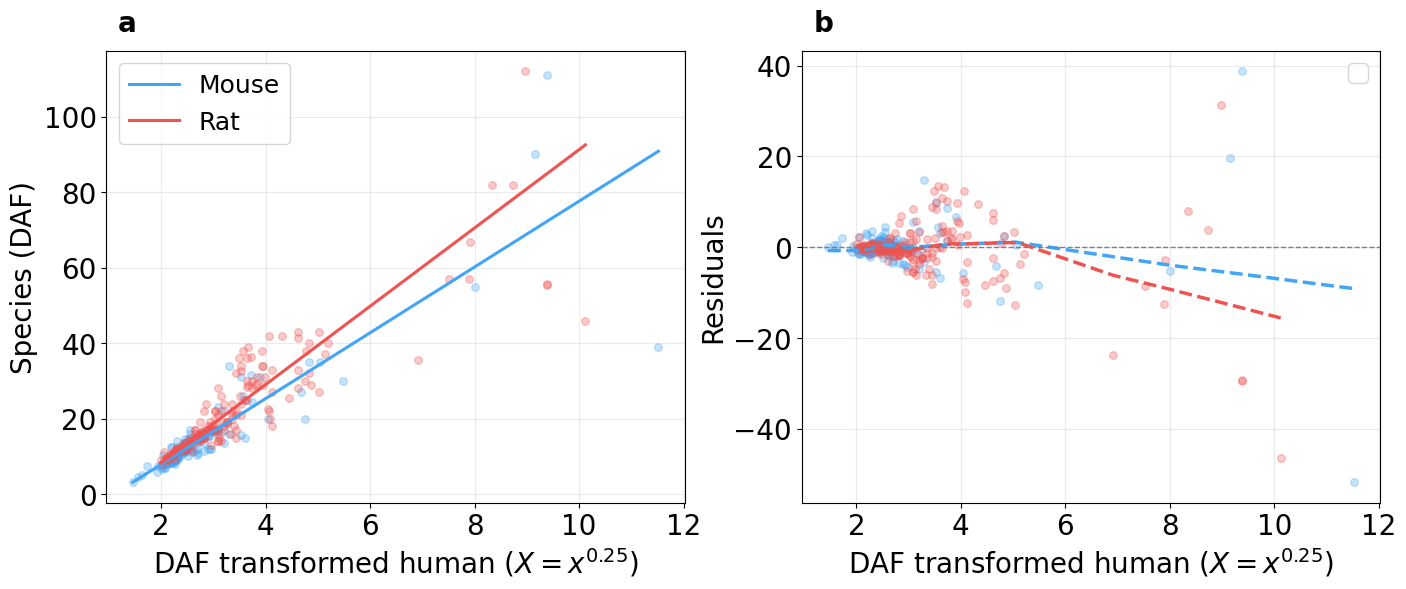

In [13]:
# 12 - Test whether the transformation X = x^0.25 linearizes the data (Diagnostic)

# ==============================================================================
# KEY CONCEPT NOTE:
# - The transformation to evaluate linearity is EXCLUSIVELY: X = x^0.25
# - The expression b*x^0.25 + c is the model PREDICTION.
#   Using the prediction as the X axis to test linearity is circular and will
#   always produce a perfect line. That's why it's not used here.
# ==============================================================================

from statsmodels.nonparametric.smoothers_lowess import lowess

# If `tabla_params` is missing, try to compute it automatically (non-fatal).
if 'tabla_params' not in globals():
    print("`tabla_params` not found. Attempting to compute WLS parameters automatically (may take a minute)...")
    try:
        df_rat_params   = tabla_parametros_wls(fit_rat['Human'],   fit_rat['Rat'],   especie='Rat')
        df_mouse_params = tabla_parametros_wls(fit_mouse['Human'], fit_mouse['Mouse'], especie='Mouse')
        tabla_params = pd.concat([df_rat_params, df_mouse_params], ignore_index=True)
        print("Computed `tabla_params` successfully. Continuing with the diagnostic.")
    except Exception as e:
        print(f"Unable to compute `tabla_params` automatically: {e}")
        print("Please run the cell that computes WLS parameters first (cell 09.5). Skipping diagnostic.")
        tabla_params = None

if tabla_params is None:
    # Nothing to do; exit gracefully without raising an error.
    print("Linearity diagnostic skipped because `tabla_params` is unavailable.")
else:
    # Create side-by-side layout: left = fits, right = residuals
    fig, (ax_fit, ax_res) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 1]}, constrained_layout=True)

    for species in ['Mouse', 'Rat']:
        sel = tabla_params[(tabla_params['Especie'] == species) & (tabla_params['Modelo'] == 'Quarter + c')]
        if sel.empty:
            print(f'No parameters for {species}. Skipping.')
            continue

        try:
            b_orig = float(sel.loc[sel['Parámetro'] == 'b', 'Estimación'].values[0])
            c_orig = float(sel.loc[sel['Parámetro'] == 'c', 'Estimación'].values[0])
        except Exception as e:
            print(f'Error extracting parameters for {species}: {e}')
            continue

        human = df_pivot['Human'].to_numpy(dtype=float)
        y_spec = df_pivot[species].to_numpy(dtype=float)

        mask = np.isfinite(human) & np.isfinite(y_spec) & (human > 0)
        if mask.sum() <= 4:
            print(f'Not enough valid points for {species}.')
            continue

        h = human[mask]
        y = y_spec[mask]

        # Pure transformation (X = x^0.25)
        X = np.power(h, 0.25)

        # ======================================================================
        # REPLICATION OF WLS WEIGHT LOGIC (from cell 09.5)
        # ======================================================================
        try:
            X_ols_const = sm.add_constant(X)
            ols_fit = sm.OLS(y, X_ols_const).fit()
            y_ols_pred = ols_fit.predict(X_ols_const)

            resid2 = np.maximum((y - y_ols_pred) ** 2, np.finfo(float).eps)
            Z = sm.add_constant(np.log(np.maximum(h, np.finfo(float).eps)))
            var_fit = sm.OLS(np.log(resid2), Z).fit()
            sigma2 = np.maximum(np.exp(var_fit.predict(Z)), np.finfo(float).eps)
            sigma = np.sqrt(sigma2)

            w = 1.0 / sigma2 
        except Exception as e:
            print(f"⚠️ Error calculating WLS weights for {species} ({e}). Using OLS (equal weights).")
            w = None 
        # ======================================================================

        color = cfg.colors.get(species, None)

        # Linear WLS model
        X_lin_const = sm.add_constant(X)
        mod_lin = sm.WLS(y, X_lin_const, weights=w).fit()
        slope_lin, intercept_lin = mod_lin.params[1], mod_lin.params[0]
        y_pred_lin = mod_lin.predict(X_lin_const)
        resid_lin = y - y_pred_lin

        # Quadratic (for diagnostics)
        X_quad = np.column_stack((X, X**2))
        X_quad_const = sm.add_constant(X_quad)
        mod_quad = sm.WLS(y, X_quad_const, weights=w).fit()
        y_pred_quad = mod_quad.predict(X_quad_const)

        # LOESS smoothing for the residuals (resid vs X)
        try:
            loess_frac = 0.8
            loess_res = lowess(resid_lin, X, frac=loess_frac, return_sorted=True)
        except Exception:
            loess_res = None

        # Plot: left axis (data and linear fit)
        ax_fit.scatter(X, y, color=color, alpha=0.3, s=30)#, label=f'{species} data'
        X_line_plot = np.linspace(np.min(X), np.max(X), 200)
        ax_fit.plot(X_line_plot, mod_lin.predict(sm.add_constant(X_line_plot)), color=color, linewidth=2.2, label=f'{species}')

        # Plot residuals on the right axis (both species share the residual panel)
        ax_res.scatter(X, resid_lin, color=color, alpha=0.3, s=30)
        if loess_res is not None:
            ax_res.plot(loess_res[:, 0], loess_res[:, 1], color=color, linewidth=2.5, linestyle='--')#, alpha=0.9, label=f'{species} LOESS residuals'

        # Print diagnostics per species
        ss_res_lin = np.sum(resid_lin**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r2_lin = 1 - (ss_res_lin / ss_tot)
        rmse_lin = np.sqrt(np.mean(resid_lin**2))
        rmse_quad = np.sqrt(np.mean((y - y_pred_quad)**2))
        aic_quad = mod_quad.aic
        aic_lin = mod_lin.aic
        delta_aic = aic_lin - aic_quad
        p_val_x2 = mod_quad.pvalues[2] if len(mod_quad.pvalues) > 2 else np.nan
        sig_x2 = "Yes" if pd.notna(p_val_x2) and p_val_x2 < 0.05 else "No"

        try:
            reset_res = linear_reset(mod_lin, power=3, use_f=True)
            f_reset = float(reset_res.fvalue)
            p_reset = float(reset_res.pvalue)
        except Exception:
            f_reset, p_reset = np.nan, np.nan

        print(f"--- {species} ---")
        print(f"  Original WLS : y = {b_orig:.4f}*X + {c_orig:.4f}")
        print(f"  Linear WLS   : y = {slope_lin:.4f}*X + {intercept_lin:.4f}  (Should be nearly identical)")
        print(f"  R² (Linear)  : {r2_lin:.4f}")
        print(f"  RMSE (Linear): {rmse_lin:.4f}")
        print(f"  Quadratic    : RMSE={rmse_quad:.4f}, ΔAIC(Linear-Quad)={delta_aic:.2f}")
        print(f"  Is X^2 term significant (p<0.05)? : {sig_x2} (p={p_val_x2:.4f})")
        print(f"  RESET F={f_reset:.4f}, p={p_reset:.4f}")
        if delta_aic > 2 and sig_x2 == "Yes":
            print(f"  ⚠️ Diagnostic: Evidence of residual curvature after x^0.25.")
        else:
            print(f"  ✅ Diagnostic: The x^0.25 transform appears to remove main curvature.")
        print("-" * 50)

    # Add lowercase subplot letters (left-to-right)
    try:
        _add_subplot_letters(np.array([ax_fit, ax_res]), subplot_letters_cfg)
    except Exception:
        # Fallback: add simple labels manually if helper missing
        ax_fit.text(0.02, 1.03, 'a', transform=ax_fit.transAxes, fontsize=FS_PANEL, fontweight='bold', ha='left', va='bottom')
        ax_res.text(0.02, 1.03, 'b', transform=ax_res.transAxes, fontsize=FS_PANEL, fontweight='bold', ha='left', va='bottom')

    # Styling and saving
    ax_fit.set_xlabel('DAF transformed human ($X = x^{0.25}$)', fontsize=FS_LABEL)
    ax_fit.set_ylabel('Species (DAF)', fontsize=FS_LABEL)
    #ax_fit.set_title('Linearity assessment: $y$ vs $X = x^{0.25}$', fontsize=FS_LABEL + 2)
    ax_fit.tick_params(axis='both', labelsize=FS_TICK)
    ax_fit.grid(True, alpha=0.25)
    ax_fit.legend(fontsize=FS_LEGEND - 2)

    ax_res.set_xlabel('DAF transformed human ($X = x^{0.25}$)', fontsize=FS_LABEL)
    ax_res.set_ylabel('Residuals', fontsize=FS_LABEL)
    ax_res.axhline(0, color='grey', linestyle='--', linewidth=1)
    ax_res.tick_params(axis='both', labelsize=FS_TICK)
    ax_res.grid(True, alpha=0.25)
    ax_res.legend(fontsize=FS_LEGEND - 2)

    plt.tight_layout()
    plt.savefig('figures/linearity_diagnostic_quarter_power_loess.pdf', bbox_inches='tight')
    plt.show()


--- Mouse ---
  Original WLS : y = 8.7156*X + -9.5489
  Linear WLS   : y = 8.5542*X + -9.1694
  R² (Linear)   : 0.7510
  RMSE (Linear): 5.4295
  Intercept    : -9.1694  (p=0.0000)  Significativo (p<0.05)? Sí
  Slope        : 8.5542  (p=0.0000)  Significativo (p<0.05)? Sí
  ΔAIC (no-intercepto - con-intercepto) = +221.79
  ✅ El intercepto ES significativo (p=0.0000 < 0.05): conservar Quarter + c.
  Quadratic    : RMSE=5.9036, ΔAIC(Linear-Quad)=-1.13
  ¿Término X² significativo (p<0.05)? : No (p=0.3544)
  RESET clásico       : F=60.9904, p=0.0000
  RESET robusto (HC3) : F=0.6569, p=0.5196
  White (heteroced.)  : LM=165.6581, p=0.0000
  ✅ No hay evidencia robusta de curvatura residual: X² no significativo (p=0.3544), ΔAIC=-1.13, RESET-robust p=0.5196.
     (RESET clásico descartado: heterocedasticidad residual detectada por White, p=0.0000).
--------------------------------------------------
--- Rat ---
  Original WLS : y = 10.3716*X + -12.4535
  Linear WLS   : y = 10.2853*X + -12.2309
  

C:\Users\acuaman\AppData\Local\Temp\ipykernel_16312\33356748.py:247: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


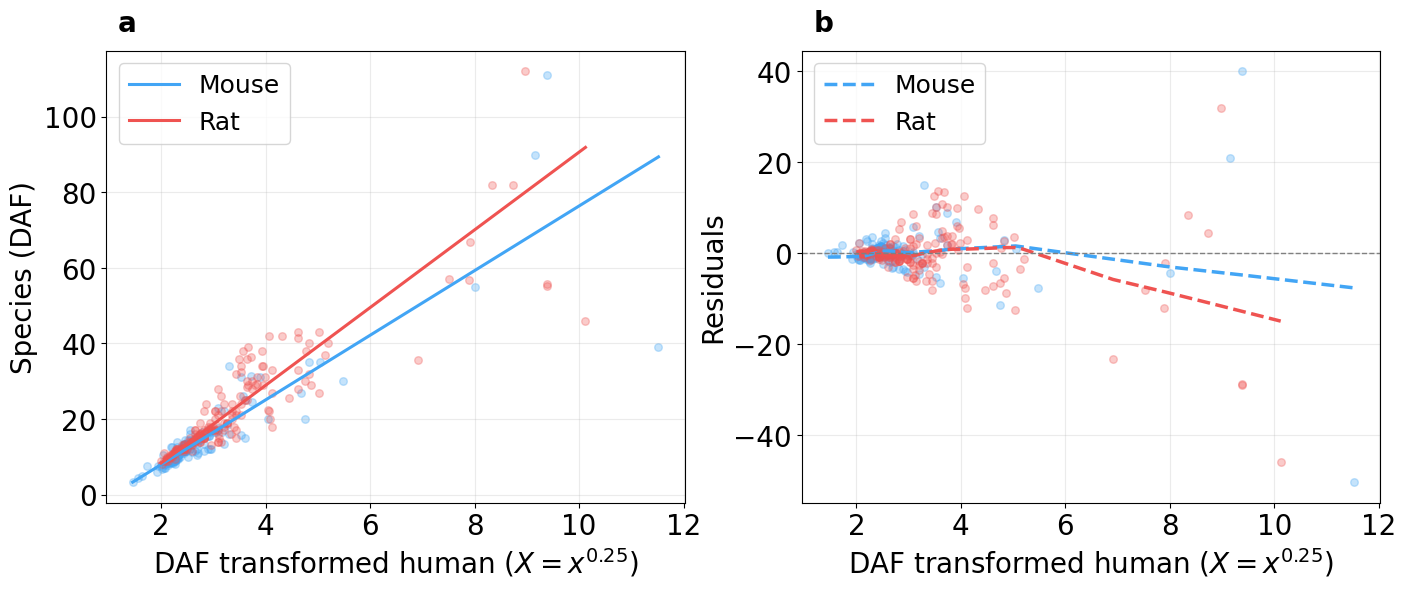

In [14]:
# 12 - Test whether the transformation X = x^0.25 linearizes the data (Diagnostic)



from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_white

# If `tabla_params` is missing, try to compute it automatically (non-fatal).
if 'tabla_params' not in globals():
    print("`tabla_params` not found. Attempting to compute WLS parameters automatically (may take a minute)...")
    try:
        df_rat_params   = tabla_parametros_wls(fit_rat['Human'],   fit_rat['Rat'],   especie='Rat')
        df_mouse_params = tabla_parametros_wls(fit_mouse['Human'], fit_mouse['Mouse'], especie='Mouse')
        tabla_params = pd.concat([df_rat_params, df_mouse_params], ignore_index=True)
        print("Computed `tabla_params` successfully. Continuing with the diagnostic.")
    except Exception as e:
        print(f"Unable to compute `tabla_params` automatically: {e}")
        print("Please run the cell that computes WLS parameters first (cell 09.5). Skipping diagnostic.")
        tabla_params = None

if tabla_params is None:
    print("Linearity diagnostic skipped because `tabla_params` is unavailable.")
else:
    fig, (ax_fit, ax_res) = plt.subplots(1, 2, figsize=(14, 6),
                                         gridspec_kw={'width_ratios': [1, 1]},
                                         constrained_layout=True)

    for species in ['Mouse', 'Rat']:
        sel = tabla_params[(tabla_params['Especie'] == species) &
                           (tabla_params['Modelo'] == 'Quarter + c')]
        if sel.empty:
            print(f'No parameters for {species}. Skipping.')
            continue

        try:
            b_orig = float(sel.loc[sel['Parámetro'] == 'b', 'Estimación'].values[0])
            c_orig = float(sel.loc[sel['Parámetro'] == 'c', 'Estimación'].values[0])
        except Exception as e:
            print(f'Error extracting parameters for {species}: {e}')
            continue

        human = df_pivot['Human'].to_numpy(dtype=float)
        y_spec = df_pivot[species].to_numpy(dtype=float)

        mask = np.isfinite(human) & np.isfinite(y_spec) & (human > 0)
        if mask.sum() <= 4:
            print(f'Not enough valid points for {species}.')
            continue

        h = human[mask]
        y = y_spec[mask]

        # Pure transformation (X = x^0.25)
        X = np.power(h, 0.25)

        # ======================================================================
        # REPLICATION OF WLS WEIGHT LOGIC (from cell 09.5)
        # ======================================================================
        try:
            X_ols_const = sm.add_constant(X)
            ols_fit = sm.OLS(y, X_ols_const).fit()
            y_ols_pred = ols_fit.predict(X_ols_const)

            resid2 = np.maximum((y - y_ols_pred) ** 2, np.finfo(float).eps)
            # Ahora (modelo de varianza en y_hat):
            yhat_pos = np.maximum(y_ols_pred, np.finfo(float).eps)
            log_yhat = np.log(yhat_pos)
            Z = sm.add_constant(log_yhat)
            var_fit = sm.OLS(np.log(resid2), Z).fit()
            sigma2 = np.maximum(np.exp(var_fit.predict(Z)), np.finfo(float).eps)
            sigma = np.sqrt(sigma2)

            w = 1.0 / sigma2
        except Exception as e:
            print(f"⚠️ Error calculating WLS weights for {species} ({e}). Using OLS (equal weights).")
            w = None
        # ======================================================================

        color = cfg.colors.get(species, None)

        # Linear WLS model
        X_lin_const = sm.add_constant(X)
        mod_lin = sm.WLS(y, X_lin_const, weights=w).fit()
        slope_lin, intercept_lin = mod_lin.params[1], mod_lin.params[0]
        y_pred_lin = mod_lin.predict(X_lin_const)
        resid_lin = y - y_pred_lin

        # ====== NUEVO: Significancia del intercepto y del slope ======
        p_intercept = float(mod_lin.pvalues[0])   # p-valor de la ordenada
        p_slope     = float(mod_lin.pvalues[1])   # p-valor de la pendiente
        sig_intercept = p_intercept < 0.05
        sig_slope     = p_slope < 0.05

        # Ajuste sin intercepto (Quarter puro) para comparar AIC
        mod_no_int = sm.WLS(y, X, weights=w).fit()
        aic_no_int  = mod_no_int.aic
        aic_lin     = mod_lin.aic
        delta_aic_int = aic_no_int - aic_lin   # >0 -> el modelo con intercepto es mejor

        # Quadratic (for diagnostics)
        X_quad = np.column_stack((X, X**2))
        X_quad_const = sm.add_constant(X_quad)
        mod_quad = sm.WLS(y, X_quad_const, weights=w).fit()
        y_pred_quad = mod_quad.predict(X_quad_const)

        # LOESS smoothing for the residuals (resid vs X)
        try:
            loess_frac = 0.8
            loess_res = lowess(resid_lin, X, frac=loess_frac, return_sorted=True)
        except Exception:
            loess_res = None

        # Plot: left axis (data and linear fit)
        ax_fit.scatter(X, y, color=color, alpha=0.3, s=30)
        X_line_plot = np.linspace(np.min(X), np.max(X), 200)
        ax_fit.plot(X_line_plot, mod_lin.predict(sm.add_constant(X_line_plot)),
                    color=color, linewidth=2.2, label=f'{species}')

        # Plot residuals on the right axis
        ax_res.scatter(X, resid_lin, color=color, alpha=0.3, s=30)
        if loess_res is not None:
            ax_res.plot(loess_res[:, 0], loess_res[:, 1],
                        color=color, linewidth=2.5, linestyle='--', label=f'{species}')

        # Print diagnostics per species
        ss_res_lin = np.sum(resid_lin**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r2_lin = 1 - (ss_res_lin / ss_tot)
        rmse_lin = np.sqrt(np.mean(resid_lin**2))
        rmse_quad = np.sqrt(np.mean((y - y_pred_quad)**2))
        aic_quad = mod_quad.aic
        delta_aic = aic_lin - aic_quad
        p_val_x2 = mod_quad.pvalues[2] if len(mod_quad.pvalues) > 2 else np.nan
        sig_x2 = "Yes" if pd.notna(p_val_x2) and p_val_x2 < 0.05 else "No"

        try:
            reset_res = linear_reset(mod_lin, power=3, use_f=True)
            f_reset = float(reset_res.fvalue)
            p_reset = float(reset_res.pvalue)
        except Exception:
            f_reset, p_reset = np.nan, np.nan

        # ---------- RESET robusto a heterocedasticidad (HC3) ----------
        try:
            y_hat = mod_lin.fittedvalues
            X_reset = np.column_stack([X, y_hat**2, y_hat**3])
            X_reset_const = sm.add_constant(X_reset)
            mod_reset = sm.WLS(y, X_reset_const, weights=w).fit(cov_type='HC3')

            # F-test conjunto de los 2 términos añadidos (y_hat^2, y_hat^3)
            r_matrix = np.zeros((2, mod_reset.params.shape[0]))
            r_matrix[0, -2] = 1   # y_hat^2
            r_matrix[1, -1] = 1   # y_hat^3
            ftest_robust = mod_reset.f_test(r_matrix)
            f_reset_robust = float(ftest_robust.fvalue)
            p_reset_robust = float(ftest_robust.pvalue)
        except Exception as e:
            print(f"⚠️ No se pudo calcular el RESET robusto para {species}: {e}")
            f_reset_robust, p_reset_robust = np.nan, np.nan

        # ---------- Test de White para heterocedasticidad residual ----------
        try:
            white_test = het_white(mod_lin.resid, X_lin_const)
            white_lm_stat = float(white_test[0])
            white_lm_p    = float(white_test[1])
        except Exception:
            white_lm_stat, white_lm_p = np.nan, np.nan

        print(f"--- {species} ---")
        print(f"  Original WLS : y = {b_orig:.4f}*X + {c_orig:.4f}")
        print(f"  Linear WLS   : y = {slope_lin:.4f}*X + {intercept_lin:.4f}")
        print(f"  R² (Linear)   : {r2_lin:.4f}")
        print(f"  RMSE (Linear): {rmse_lin:.4f}")
        print(f"  Intercept    : {intercept_lin:.4f}  (p={p_intercept:.4f})  "
              f"Significativo (p<0.05)? {'Sí' if sig_intercept else 'No'}")
        print(f"  Slope        : {slope_lin:.4f}  (p={p_slope:.4f})  "
              f"Significativo (p<0.05)? {'Sí' if sig_slope else 'No'}")
        print(f"  ΔAIC (no-intercepto - con-intercepto) = {delta_aic_int:+.2f}")
        if not sig_intercept:
            print(f"  💡 El intercepto NO es significativo (p={p_intercept:.4f} ≥ 0.05).")
            if delta_aic_int < 2:
                print(f"     Además ΔAIC = {delta_aic_int:+.2f} < 2: el modelo sin "
                      f"intercepto es comparable o mejor.")
                print(f"     → Recomendación: usar Quarter puro  y = b * x^0.25.")
            else:
                print(f"     Pero ΔAIC = {delta_aic_int:+.2f} ≥ 2: el modelo con "
                      f"intercepto sigue siendo claramente mejor por AIC.")
                print(f"     → Recomendación: conservar Quarter + c  y = b * x^0.25 + c.")
        else:
            print(f"  ✅ El intercepto ES significativo (p={p_intercept:.4f} < 0.05): "
                  f"conservar Quarter + c.")

        print(f"  Quadratic    : RMSE={rmse_quad:.4f}, "
              f"ΔAIC(Linear-Quad)={delta_aic:.2f}")
        print(f"  ¿Término X² significativo (p<0.05)? : {sig_x2} (p={p_val_x2:.4f})")
        print(f"  RESET clásico       : F={f_reset:.4f}, p={p_reset:.4f}")
        print(f"  RESET robusto (HC3) : F={f_reset_robust:.4f}, p={p_reset_robust:.4f}")
        print(f"  White (heteroced.)  : LM={white_lm_stat:.4f}, p={white_lm_p:.4f}")

        # Decisión final basada en los tests confiables (sin reimprimir el RESET)
        curvature_quad = (delta_aic > 2) and (sig_x2 == "Yes")
        curvature_reset_robust = (pd.notna(p_reset_robust) and p_reset_robust < 0.05)
        reset_unreliable = (pd.notna(white_lm_p) and white_lm_p < 0.05)

        if curvature_quad:
            print(f"  ⚠️ Curvatura cuadrática significativa: ΔAIC={delta_aic:.2f}, "
                  f"p(X²)={p_val_x2:.4f}.")
        elif curvature_reset_robust and not reset_unreliable:
            print(f"  ⚠️ El RESET robusto (HC3) rechaza linealidad (p={p_reset_robust:.4f}): "
                  f"posible curvatura de orden superior.")
        elif curvature_reset_robust and reset_unreliable:
            print(f"  ⚠️ RESET robusto rechaza (p={p_reset_robust:.4f}), PERO el test de White "
                  f"también rechaza homocedasticidad (p={white_lm_p:.4f}). "
                  f"No se puede separar curvatura de heterocedasticidad.")
        else:
            print(f"  ✅ No hay evidencia robusta de curvatura residual: "
                  f"X² no significativo (p={p_val_x2:.4f}), "
                  f"ΔAIC={delta_aic:.2f}, RESET-robust p={p_reset_robust:.4f}.")
            if reset_unreliable:
                print(f"     (RESET clásico descartado: heterocedasticidad residual detectada "
                      f"por White, p={white_lm_p:.4f}).")
        print("-" * 50)

    # Add lowercase subplot letters (left-to-right)
    try:
        _add_subplot_letters(np.array([ax_fit, ax_res]), subplot_letters_cfg)
    except Exception:
        ax_fit.text(0.02, 1.03, 'a', transform=ax_fit.transAxes,
                    fontsize=FS_PANEL, fontweight='bold', ha='left', va='bottom')
        ax_res.text(0.02, 1.03, 'b', transform=ax_res.transAxes,
                    fontsize=FS_PANEL, fontweight='bold', ha='left', va='bottom')

    # Styling and saving
    ax_fit.set_xlabel('DAF transformed human ($X = x^{0.25}$)', fontsize=FS_LABEL)
    ax_fit.set_ylabel('Species (DAF)', fontsize=FS_LABEL)
    ax_fit.tick_params(axis='both', labelsize=FS_TICK)
    ax_fit.grid(True, alpha=0.25)
    ax_fit.legend(fontsize=FS_LEGEND - 2)

    ax_res.set_xlabel('DAF transformed human ($X = x^{0.25}$)', fontsize=FS_LABEL)
    ax_res.set_ylabel('Residuals', fontsize=FS_LABEL)
    ax_res.axhline(0, color='grey', linestyle='--', linewidth=1)
    ax_res.tick_params(axis='both', labelsize=FS_TICK)
    ax_res.grid(True, alpha=0.25)
    ax_res.legend(fontsize=FS_LEGEND - 2)

    plt.tight_layout()
    plt.savefig('figures/linearity_diagnostic_quarter_power_loess.pdf',
                bbox_inches='tight')
    plt.show()


In [15]:
# 09 - Test de sensibilidad: One-step FGLS vs IRLS
#
# One-step FGLS:
#     OLS -> estimar varianza -> WLS -> terminar
#
# IRLS:
#     OLS -> estimar varianza -> WLS
#         -> actualizar residuos -> nueva varianza -> WLS -> ...
#         -> hasta convergencia

def _wls_fit_irls(func, x, y, p0, max_iter=50, tol=1e-8, maxfev=40000):
    """
    Ajuste iterativo FGLS/IRLS.

    En cada iteración:
        1. Calcula residuos del ajuste actual.
        2. Estima log(sigma^2) ~ log(x).
        3. Reajusta el modelo mediante WLS.
        4. Comprueba convergencia de los parámetros.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    eps = np.finfo(float).eps

    # ---------------------------------------------------------
    # 1. Ajuste inicial OLS
    # ---------------------------------------------------------
    try:
        p_current, _ = curve_fit(
            func,
            x,
            y,
            p0=p0,
            maxfev=maxfev
        )
    except RuntimeError:
        return None

    converged = False
    n_iter = 0

    # ---------------------------------------------------------
    # 2. Iteraciones IRLS
    # ---------------------------------------------------------
    for iteration in range(max_iter):

        n_iter = iteration + 1

        # Residuos del ajuste actual
        y_current = func(x, *p_current)
        residuals = y - y_current

        resid2 = np.maximum(residuals ** 2, eps)
        log_x = np.log(np.maximum(x, eps))

        # -----------------------------------------------------
        # Estimar función de varianza
        # log(sigma^2) = c0 + c1 * log(x)
        # -----------------------------------------------------
        Z = sm.add_constant(log_x)

        var_fit = sm.OLS(
            np.log(resid2),
            Z
        ).fit()

        c0, c1 = var_fit.params

        sigma2_hat = np.maximum(
            np.exp(var_fit.predict(Z)),
            eps
        )

        sigma_hat = np.sqrt(sigma2_hat)

        # -----------------------------------------------------
        # Nuevo ajuste WLS
        # -----------------------------------------------------
        try:
            p_new, _ = curve_fit(
                func,
                x,
                y,
                p0=p_current,
                sigma=sigma_hat,
                absolute_sigma=False,
                maxfev=maxfev
            )
        except RuntimeError:
            return None

        # -----------------------------------------------------
        # Criterio de convergencia
        # -----------------------------------------------------
        parameter_change = np.max(
            np.abs(p_new - p_current)
            / np.maximum(np.abs(p_current), eps)
        )

        p_current = p_new

        if parameter_change < tol:
            converged = True
            break

    # ---------------------------------------------------------
    # 3. Calcular resultados finales
    # ---------------------------------------------------------
    y_final = func(x, *p_current)
    residuals_final = y - y_final

    resid2_final = np.maximum(
        residuals_final ** 2,
        eps
    )

    log_x = np.log(np.maximum(x, eps))
    Z = sm.add_constant(log_x)

    var_fit_final = sm.OLS(
        np.log(resid2_final),
        Z
    ).fit()

    c0_final, c1_final = var_fit_final.params

    sigma2_final = np.maximum(
        np.exp(var_fit_final.predict(Z)),
        eps
    )

    weights_final = 1.0 / sigma2_final

    wsrs_final = np.sum(
        weights_final * residuals_final ** 2
    )

    wrmse_final = np.sqrt(
        wsrs_final / np.sum(weights_final)
    )

    return {
        'params': p_current,
        'y_fit': y_final,
        'weights': weights_final,
        'sigma2': sigma2_final,
        'wrmse': wrmse_final,
        'c0': c0_final,
        'c1': c1_final,
        'iterations': n_iter,
        'converged': converged
    }


def test_one_step_vs_irls(x, y, especie):
    """
    Compara el ajuste one-step FGLS utilizado actualmente
    con un ajuste IRLS iterativo, usando todos los datos.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    model_order = ['M3', 'M1', 'M5', 'M4', 'M2']

    rows = []

    for mid in model_order:

        mspec = cfg.MODELS.get(mid)

        if mspec is None:
            continue

        name = mspec.get('name', mid)
        equation = mspec.get('equation', '')
        eqnum = mspec.get('equation_number')
        p0 = list(mspec.get('initial_params', []))

        func_name = mspec.get('function')

        if (
            isinstance(func_name, str)
            and hasattr(cfg, func_name)
        ):
            func = getattr(cfg, func_name)
        else:
            func = func_name

        # =====================================================
        # ONE-STEP FGLS
        # =====================================================

        result_one = _wls_fit_single(
            func,
            x,
            y,
            p0=p0,
            maxfev=40000
        )

        if result_one is None:
            continue

        p_one = result_one[0]
        wrmse_one = np.sqrt(
            result_one[3] / np.sum(result_one[2])
        )

        c0_one = result_one[5]
        c1_one = result_one[6]

        # =====================================================
        # IRLS
        # =====================================================

        result_irls = _wls_fit_irls(
            func,
            x,
            y,
            p0=p0,
            max_iter=50,
            tol=1e-8,
            maxfev=40000
        )

        if result_irls is None:
            continue

        p_irls = result_irls['params']

        # =====================================================
        # Diferencia relativa de parámetros
        # =====================================================

        relative_change = (
            np.abs(p_irls - p_one)
            / np.maximum(np.abs(p_one), np.finfo(float).eps)
        )

        max_relative_change = np.max(relative_change)

        # =====================================================
        # Guardar resultados
        # =====================================================

        row = {
            'Model_ID': mid,
            'Model': name,
            'Eq': f"({eqnum})" if eqnum is not None else '-',
            'One-step WRMSE': wrmse_one,
            'IRLS WRMSE': result_irls['wrmse'],
            'WRMSE difference': (
                result_irls['wrmse'] - wrmse_one
            ),
            'IRLS iterations': result_irls['iterations'],
            'IRLS converged': result_irls['converged'],
            'Variance slope one-step': c1_one,
            'Variance slope IRLS': result_irls['c1'],
            'Max relative parameter change': max_relative_change
        }

        # Guardar parámetros individualmente
        for j in range(len(p_one)):
            row[f'p{j+1} one-step'] = p_one[j]
            row[f'p{j+1} IRLS'] = p_irls[j]
            row[f'p{j+1} relative change'] = relative_change[j]

        rows.append(row)

    tabla_test = pd.DataFrame(rows)

    print(f'\n{"=" * 100}')
    print(f' {especie.upper()} | SENSIBILIDAD: ONE-STEP FGLS vs IRLS')
    print(f'{"=" * 100}')

    columnas = [
        'Model_ID',
        'Model',
        'One-step WRMSE',
        'IRLS WRMSE',
        'WRMSE difference',
        'IRLS iterations',
        'IRLS converged',
        'Variance slope one-step',
        'Variance slope IRLS',
        'Max relative parameter change'
    ]

    tabla_print = tabla_test[columnas].copy()

    for col in [
        'One-step WRMSE',
        'IRLS WRMSE',
        'WRMSE difference',
        'Variance slope one-step',
        'Variance slope IRLS',
        'Max relative parameter change'
    ]:
        tabla_print[col] = tabla_print[col].map(
            lambda value: f"{value:.6g}"
        )

    print(tabla_print.to_string(index=False))

    print(f'{"=" * 100}\n')

    return tabla_test


# =============================================================
# EJECUTAR EL TEST
# =============================================================

irls_rat = test_one_step_vs_irls(
    fit_rat['Human'],
    fit_rat['Rat'],
    especie='Rat'
)

irls_mouse = test_one_step_vs_irls(
    fit_mouse['Human'],
    fit_mouse['Mouse'],
    especie='Mouse'
)


 RAT | SENSIBILIDAD: ONE-STEP FGLS vs IRLS
Model_ID       Model One-step WRMSE IRLS WRMSE WRMSE difference  IRLS iterations  IRLS converged Variance slope one-step Variance slope IRLS Max relative parameter change
      M3   Power + c        2.26033    1.55744        -0.702889               50           False                 1.16402             1.77222                      0.681284
      M1       Power        3.70599    1.41918         -2.28681                7            True                0.592653             1.94719                      0.353171
      M5 Logarithmic         3.1025    1.85678         -1.24572               50           False                 0.76723             1.58585                      0.263774
      M4 Quarter + c        2.60989    1.70729        -0.902598                6            True                0.948817             1.62424                     0.0216125
      M2     Quarter        5.39354    4.24259         -1.15095               15            True     